# SC4020 · Run 2 v6 | Historical Graph Construction & Faceted EDA

**Datasets:** EuroMart Retail (quarterly) and Retail POS (monthly)  
**Role in project:** graph visualisation / EDA for both datasets  
**Run policy:** retain the exact graphs used in the completed model comparisons.

### What this notebook does

1. Audits the three cleaned EuroMart split files and **reconstructs 15 quarterly snapshots** (2011Q2–2014Q4) with the original Run 2 v5 semantics.
2. Validates and **reuses the frozen 12 monthly Retail POS snapshots** from Run 2 v3 (including source-file hashes). This avoids changing the already evaluated monthly graph.
3. Produces comparable descriptive tables and evolution plots for both snapshot series.
4. Reproduces Run 9's submission-ready **seven-panel (A–G) faceted figures**, one per dataset, using final *historical* snapshots only:
   - **A–B:** same 100 sampled eligible customers (network and adjacency matrix);
   - **C–G:** complete graph statistics, Jaccard matrix, customer and category node features.
5. Exports **PNG, PDF, SVG, sampling CSVs and a compact ZIP**.

**Leakage rule:** connections and node features for target time *t* come strictly from purchases before *t*. The targets/labels are *not* plotted as historical graph edges.

**Compatibility:** EuroMart graph artifacts remain under `graph_data/v5/euromart/quarterly/`, and Retail POS graph artifacts remain under `graph_data/v3/retail_pos/monthly/`; only visual outputs are new (`results/v6/run2_graphs/`). The notebook never overwrites incompatible existing graph snapshots. This is a **v6 notebook/workflow**, not a new feature contract for downstream GNN models.

**Before Run All:** use the existing repository with `data/v3/processed/euromart_{train,val,test}.csv` and `graph_data/v3/retail_pos/` present. If Colab cannot locate it, edit `REPO_ROOT_OVERRIDE` in the first code cell. Standard Python packages: NumPy, pandas, matplotlib, SciPy, IPython.

## 1. Environment, reproducible paths, and EuroMart source audit

In [1]:
from __future__ import annotations
import os, json, hashlib, sys, math, platform
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO_ROOT_OVERRIDE = None    # e.g. '/content/drive/MyDrive/SC4020-DataMining'
SOURCE_DIR_OVERRIDE = None   # folder holding the three cleaned CSVs, if moved
SOURCE_FILES = ['euromart_train.csv','euromart_val.csv','euromart_test.csv']
SEED = 42
np.random.seed(SEED)

def locate_root():
    try:
        from google.colab import drive
        if not Path('/content/drive/MyDrive').exists(): drive.mount('/content/drive')
    except ImportError:
        pass
    paths = [REPO_ROOT_OVERRIDE, os.environ.get('SC4020_REPO_ROOT'),
             '/content/drive/MyDrive/SC4020-DataMining', '/content/SC4020-DataMining',
             Path.cwd(), Path.cwd().parent]
    for p in paths:
        if p and (Path(p)/'graph_data/v3/retail_pos/snapshot_index.csv').exists():
            return Path(p).resolve()
    raise FileNotFoundError('Repository missing; set REPO_ROOT_OVERRIDE to SC4020-DataMining.')

def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as fh:
        for b in iter(lambda:fh.read(1024*1024),b''):h.update(b)
    return h.hexdigest()

def write_json(path,obj):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    path.write_text(json.dumps(obj,indent=2,default=lambda x: x.item() if isinstance(x,np.generic) else str(x)))

ROOT=locate_root()
SOURCE_DIR=Path(SOURCE_DIR_OVERRIDE) if SOURCE_DIR_OVERRIDE else ROOT/'data/v3/processed'
PROCESSED=ROOT/'data/v5/processed'
EURO=ROOT/'graph_data/v5/euromart'
SNAPDIR=EURO/'quarterly'
RUN2=ROOT/'results/v6/run2_graphs'
for folder in (PROCESSED,SNAPDIR,RUN2/'figures',RUN2/'tables',RUN2/'manifests'):
    folder.mkdir(parents=True,exist_ok=True)
SRC=[SOURCE_DIR/f for f in SOURCE_FILES]
for p in SRC:
    if not p.exists():raise FileNotFoundError('Missing cleaned CSV: '+str(p))
print('Repository:',ROOT,'\nEuroMart source:',SOURCE_DIR,'\nNew visualisation output:',RUN2)

EXPECTED_COLUMNS={'Order ID','Order Date','cust_id','Sub-Category','subcat_id',
                  'Quantity','Sales','quarter','q_idx','split'}
frames=[];source_audit=[]
for name,p in zip(('train','val','test'),SRC):
    df=pd.read_csv(p)
    if not EXPECTED_COLUMNS.issubset(df.columns):
        raise ValueError(f'{p.name}: missing columns {EXPECTED_COLUMNS-set(df.columns)}')
    if not df['split'].astype(str).eq(name).all():
        raise ValueError(f'{p.name}: split label disagrees with its file')
    df['Order Date']=pd.to_datetime(df['Order Date'],errors='raise')
    if df[list(EXPECTED_COLUMNS-{'Order Date'})].isna().any().any():
        raise ValueError(f'{p.name}: nulls in mandatory columns')
    if not np.isfinite(df[['Sales','Quantity']].to_numpy(dtype=float)).all():
        raise ValueError('Nonfinite quantity/sales')
    if (df[['Sales','Quantity']]<0).any().any():
        raise ValueError('Negative totals require review before log1p transformations')
    period=df['Order Date'].dt.to_period('Q')
    if not (period.astype(str)==df['quarter'].astype(str)).all():
        raise ValueError(f'{p.name}: quarter column disagrees with transaction dates')
    if df.duplicated().any():
        raise ValueError(f'{p.name}: duplicated complete input rows')
    frames.append(df)
    source_audit.append(dict(file=p.name,sha256=sha256(p),rows=len(df),
           first_date=str(df['Order Date'].min().date()),last_date=str(df['Order Date'].max().date())))
transactions=pd.concat(frames,ignore_index=True)
transactions=transactions.sort_values(['Order Date','Order ID','cust_id','subcat_id'],kind='mergesort').reset_index(drop=True)
if transactions.duplicated().any():raise AssertionError('Duplicates introduced through merge')
if transactions['cust_id'].nunique()!=792 or transactions['Sub-Category'].nunique()!=17:
    raise AssertionError('Unexpected customer/category cardinalities; inspect new source version')
if transactions.groupby('cust_id')['Customer Name'].nunique().max()!=1:
    raise AssertionError('cust_id and name mapping unstable')
if transactions.groupby('Sub-Category')['subcat_id'].nunique().max()!=1:
    raise AssertionError('subcat_id and category mapping unstable')
train_quarters=[str(q) for q in pd.period_range('2011Q2','2013Q3',freq='Q')]
val_quarters=['2013Q4','2014Q1'];test_quarters=['2014Q2','2014Q3','2014Q4']
splits={'train':train_quarters,'val':val_quarters,'test':test_quarters}
expected={'train':set(['2011Q1']+train_quarters),'val':set(val_quarters),'test':set(test_quarters)}
for split,qs in expected.items():
    actual=set(transactions.loc[transactions.split==split,'quarter'].astype(str))
    if actual!=qs:raise AssertionError(f'{split}: quarters {sorted(actual)} != {sorted(qs)}')
if str(transactions['Order Date'].min().to_period('Q'))!='2011Q1':
    raise AssertionError('Missing 2011Q1 warm-up history')
canonical=transactions.copy();canonical['Order Date']=canonical['Order Date'].dt.strftime('%Y-%m-%d')
canonical.to_csv(PROCESSED/'euromart_transactions_v5.csv',index=False)
write_json(RUN2/'manifests/source_audit.json',{'source_files':source_audit,
            'merged_rows':len(canonical),'merged_sha256':sha256(PROCESSED/'euromart_transactions_v5.csv'),
            'quarterly_split':splits,'warmup':'2011Q1','source':'three supplied cleaned split CSVs'})
print('Merged',len(canonical),'rows; 792 customers; 17 subcategories; source hashes recorded')
display(pd.DataFrame(source_audit))

Mounted at /content/drive
Repository: /content/drive/MyDrive/SC4020-DataMining 
EuroMart source: /content/drive/MyDrive/SC4020-DataMining/data/v3/processed 
New visualisation output: /content/drive/MyDrive/SC4020-DataMining/results/v6/run2_graphs
Merged 8042 rows; 792 customers; 17 subcategories; source hashes recorded


,file,sha256,rows,first_date,last_date
0,euromart_train.csv,78eca533b3d8aa45913634697226dd7ac2ae3d9bea8561...,4885,2011-01-01,2013-09-30
1,euromart_val.csv,29747a4a2d13057d57918a681dc6da306f65f76c3836b0...,990,2013-10-01,2014-03-31
2,euromart_test.csv,30ae288df77a4d06fa03a45afb975f9b6488b9b81b4866...,2167,2014-04-01,2014-12-31


## 2. EuroMart registry, pre-target node features, and quarterly graph snapshots

Reuses the tested v5 feature definitions, binary edge construction, chronological splits and customer-eligibility rule. The `target_month` key is retained for downstream compatibility, even though EuroMart values are **quarters**.

In [2]:
PERIODS=[str(q) for q in pd.period_range('2011Q2','2014Q4',freq='Q')]
F_CUSTOMER=['log_interactions','log_orders','log_quantity','log_value',
            'category_diversity_fraction','active_period_fraction','freshness']
F_CATEGORY=['log_interactions','log_orders','log_quantity','log_value',
            'log_unique_customers','popularity_share','freshness']
CUSTOMERS=(transactions[['cust_id','Customer Name']].drop_duplicates()
           .sort_values('cust_id',kind='mergesort').reset_index(drop=True))
CUSTOMERS['customer_id']=CUSTOMERS['cust_id'].astype(str)
CUSTOMERS['customer_idx']=np.arange(len(CUSTOMERS),dtype=int)
CUSTOMERS['node_idx']=CUSTOMERS.customer_idx
CATEGORIES=(transactions[['subcat_id','Sub-Category']].drop_duplicates()
            .sort_values('subcat_id').reset_index(drop=True))
CATEGORIES['category']=CATEGORIES['Sub-Category'].astype(str)
CATEGORIES['category_idx']=np.arange(len(CATEGORIES),dtype=int)
if not np.array_equal(CATEGORIES['subcat_id'].astype(int).to_numpy(),np.arange(17)):
    raise ValueError('Unexpected subcategory numbering; require explicit audited mapping')
CATEGORIES['node_idx']=len(CUSTOMERS)+CATEGORIES.category_idx
CUSTOMERS['first_seen_period']=CUSTOMERS.customer_id.map(
    transactions.assign(customer_id=transactions.cust_id.astype(str)).groupby('customer_id')['Order Date'].min().dt.to_period('Q').astype(str))
CATEGORIES['first_seen_period']=CATEGORIES.category.map(transactions.groupby('Sub-Category')['Order Date'].min().dt.to_period('Q').astype(str))
last_training='2013Q3'
CUSTOMERS['seen_in_any_train_input_graph']=pd.PeriodIndex(CUSTOMERS.first_seen_period,freq='Q')<pd.Period(last_training,freq='Q')
CATEGORIES['seen_in_any_train_input_graph']=pd.PeriodIndex(CATEGORIES.first_seen_period,freq='Q')<pd.Period(last_training,freq='Q')
CUSTOMERS.to_csv(EURO/'customer_registry.csv',index=False)
CATEGORIES.to_csv(EURO/'category_registry.csv',index=False)
customer_to_idx=dict(zip(CUSTOMERS.customer_id,CUSTOMERS.customer_idx))
category_to_idx=dict(zip(CATEGORIES.category,CATEGORIES.category_idx))
T=transactions.assign(customer_id=transactions.cust_id.astype(str),category=transactions['Sub-Category'].astype(str),
                      order_id=transactions['Order ID'].astype(str),quantity=transactions.Quantity.astype(float),
                      value_proxy=transactions.Sales.astype(float),quarter_period=transactions['Order Date'].dt.to_period('Q'))

def freshness(last,target):
    inactive=max(pd.Period(target,freq='Q').ordinal-pd.Period(last,freq='Q').ordinal-1,0)
    return 1.0/(1+inactive)

def make_snapshot(target):
    target_q=pd.Period(target,freq='Q')
    hist=T[T.quarter_period<target_q]
    outcome=T[T.quarter_period==target_q]
    assert len(hist) and len(outcome)
    ncu=len(CUSTOMERS)
    cu=np.zeros((ncu,7),np.float32);ca=np.zeros((17,7),np.float32)
    hc=np.zeros(ncu,bool);hk=np.zeros(17,bool)
    cagg=hist.groupby('customer_id').agg(interactions=('category','size'),orders=('order_id','nunique'),
       quantity=('quantity','sum'),value=('value_proxy','sum'),diversity=('category','nunique'),
       active_periods=('quarter_period','nunique'),first=('quarter_period','min'),last=('quarter_period','max'))
    for key,r in cagg.iterrows():
        ix=customer_to_idx[key];hc[ix]=True
        span=max(target_q.ordinal-r['first'].ordinal,1)
        cu[ix]=[np.log1p(r.interactions),np.log1p(r.orders),np.log1p(r.quantity),
                np.log1p(r.value),r.diversity/17,r.active_periods/span,freshness(r['last'],target_q)]
    kagg=hist.groupby('category').agg(interactions=('customer_id','size'),orders=('order_id','nunique'),
       quantity=('quantity','sum'),value=('value_proxy','sum'),uniques=('customer_id','nunique'),
       last=('quarter_period','max'))
    for key,r in kagg.iterrows():
        ix=category_to_idx[key];hk[ix]=True
        ca[ix]=[np.log1p(r.interactions),np.log1p(r.orders),np.log1p(r.quantity),
                np.log1p(r.value),np.log1p(r.uniques),r.interactions/len(hist),freshness(r['last'],target_q)]
    pairs=hist[['customer_id','category']].drop_duplicates().copy()
    bip=np.stack((pairs.customer_id.map(customer_to_idx).to_numpy(np.int64),
                  pairs.category.map(category_to_idx).to_numpy(np.int64)),axis=0)
    order=np.lexsort((bip[1],bip[0]));bip=bip[:,order]
    directed=np.concatenate((np.stack((bip[0],bip[1]+ncu)),
                             np.stack((bip[1]+ncu,bip[0]))),axis=1)
    target_active=set(outcome.customer_id);history_active=set(hist.customer_id)
    elig=sorted(target_active.intersection(history_active),key=customer_to_idx.get)
    eligible_idx=np.asarray([customer_to_idx[c] for c in elig],np.int64)
    label=np.zeros((len(elig),17),np.uint8)
    row_for={cid:i for i,cid in enumerate(elig)}
    for cid,category in outcome[['customer_id','category']].drop_duplicates().itertuples(index=False,name=None):
        if cid in row_for:label[row_for[cid],category_to_idx[category]]=1
    assert (label.sum(axis=1)>0).all()
    adjacency=np.zeros((ncu,17),np.uint8);adjacency[bip[0],bip[1]]=1
    earlier=adjacency[eligible_idx].copy()
    prevq=target_q-1
    prevpairs=hist[hist.quarter_period==prevq][['customer_id','category']].drop_duplicates()
    prev=np.zeros((len(elig),17),np.uint8)
    for cid,category in prevpairs.itertuples(index=False,name=None):
        if cid in row_for:prev[row_for[cid],category_to_idx[category]]=1
    assert (prev<=earlier).all()
    deg=np.bincount(bip[0],minlength=ncu).astype(np.int16)
    catdeg=np.bincount(bip[1],minlength=17).astype(np.int32)
    sc=dict(target_month=target,split=next(k for k,v in splits.items() if target in v),
        history_rows=len(hist),target_rows=len(outcome),historical_customers=int(hc.sum()),
        historical_categories=int(hk.sum()),unique_edges=bip.shape[1],
        density_fixed_17=float(bip.shape[1]/(int(hc.sum())*17)),
        mean_customer_degree=float(bip.shape[1]/int(hc.sum())),
        eligible_customers=len(elig),positive_pairs=int(label.sum()),candidate_pairs=int(label.size),
        positive_prevalence=float(label.mean()) if label.size else 0.,
        repeated_positive_pairs=int((label*earlier).sum()),
        novel_positive_pairs=int((label*(1-earlier)).sum()),
        previous_period_positive_pairs=int((label*prev).sum()),
        usable_for_supervision=bool(len(elig)>0))
    arrays=dict(edge_index_bipartite=bip,edge_index=directed,
        customer_features_raw=cu,category_features_raw=ca,
        history_customer_mask=hc,history_category_mask=hk,
        customer_history_degree=deg,category_history_degree=catdeg,
        eligible_customer_idx=eligible_idx,labels=label,
        eligible_history_pair_mask=earlier,eligible_previous_month_mask=prev,
        eligible_history_degree=deg[eligible_idx],
        train_seen_customer_mask=CUSTOMERS.seen_in_any_train_input_graph.to_numpy(bool),
        train_seen_category_mask=CATEGORIES.seen_in_any_train_input_graph.to_numpy(bool),
        eligible_train_seen_customer_mask=CUSTOMERS.seen_in_any_train_input_graph.to_numpy(bool)[eligible_idx])
    assert not any('edge_attr' in k or any(w in k for w in ['history_interaction_count','history_order_count',
                                    'history_quantity','history_value','history_freshness']) for k in arrays)
    assert np.all((label==0)|(label==1)) and np.isfinite(cu).all() and np.isfinite(ca).all()
    return arrays,sc

RAW={};rows=[]
for q in PERIODS:
    arrays,meta=make_snapshot(q);RAW[q]=arrays;rows.append(meta)
INDEX=pd.DataFrame(rows)
assert len(INDEX)==15 and INDEX.groupby('split').size().to_dict()=={'train':10,'val':2,'test':3}
assert (INDEX.positive_pairs==INDEX.repeated_positive_pairs+INDEX.novel_positive_pairs).all()
print('Built',len(INDEX),'quarterly snapshots; temporal split and repeated/novel counts validated.')
display(INDEX.groupby('split')[['eligible_customers','positive_pairs','candidate_pairs']].sum())

Built 15 quarterly snapshots; temporal split and repeated/novel counts validated.


,eligible_customers,positive_pairs,candidate_pairs
split,,,
test,872,1914,14824
train,1396,2930,23732
val,445,868,7565


## 3. Training-history scaling, class weight and immutable NPZ export

Scalers are fitted using **training-period history only**. Existing v5 NPZs are compared array-by-array and are never silently overwritten.

In [3]:
def fit_scaler(axis,mask):
    active=[RAW[q][axis][RAW[q][mask]] for q in train_quarters if RAW[q][mask].any()]
    a=np.concatenate(active,axis=0).astype(np.float64)
    mu=a.mean(axis=0);sd=a.std(axis=0);sd=np.where(sd<1e-12,1,sd)
    return {'mean':mu,'std':sd}

SCALERS={'customer':fit_scaler('customer_features_raw','history_customer_mask'),
         'category':fit_scaler('category_features_raw','history_category_mask')}
weights=[]
for q in train_quarters:
    yy=RAW[q]['labels'];weights.append(yy.reshape(-1))
trainy=np.concatenate(weights)
pos=int(trainy.sum());neg=int(len(trainy)-pos)
if pos<=0 or neg<=0:raise AssertionError('Degenerate training BCE prevalence')
loss={'train_eligible_customer_periods':int(sum(len(RAW[q]['eligible_customer_idx']) for q in train_quarters)),
      'train_positive_pairs':pos,'train_negative_pairs':neg,'train_candidate_pairs':len(trainy),
      'train_positive_prevalence':float(pos/len(trainy)),
      'primary_scalar_pos_weight':float(neg/pos)}

for q in PERIODS:
    arrays=RAW[q]
    for kind,arrname,mask in [('customer','customer_features_raw','history_customer_mask'),
                               ('category','category_features_raw','history_category_mask')]:
        sc=SCALERS[kind]
        standard=(arrays[arrname].astype(float)-sc['mean'])/sc['std']
        standard[~arrays[mask]]=0
        arrays[kind+'_features']=standard.astype(np.float32)
    assert np.isfinite(arrays['customer_features']).all()
    assert np.isfinite(arrays['category_features']).all()

# Do not delete any prior v5 snapshot: reject incompatible pre-existing output instead.
indexed=[]
for q,meta in zip(PERIODS,rows):
    output=SNAPDIR/(q+'.npz')
    if output.exists():
        with np.load(output,allow_pickle=False) as z:
            assert all(k in z.files and np.array_equal(z[k],v) for k,v in RAW[q].items()), \
                f'Existing {output} conflicts with current sources; archive/rename the v5 destination first.'
    else:np.savez_compressed(output,**RAW[q])
    indexed.append({**meta,'snapshot_file':output.name,'snapshot_sha256':sha256(output)})
INDEX=pd.DataFrame(indexed)
INDEX.to_csv(EURO/'snapshot_index.csv',index=False)
write_json(EURO/'feature_scalers.json',{'contract_version':'5.0','scaling':'train_history_zscore',
 'customer':{'feature_names':F_CUSTOMER,**{k:v.tolist() for k,v in SCALERS['customer'].items()}},
 'category':{'feature_names':F_CATEGORY,**{k:v.tolist() for k,v in SCALERS['category'].items()}},
 'edge_features':None,'pair_features':None})
write_json(EURO/'loss_diagnostics.json',loss)
write_json(RUN2/'manifests/run2_v5_contract.json',{'version':'5.0',
 'euromart':{'snapshot_root':'graph_data/v5/euromart/quarterly','index':'graph_data/v5/euromart/snapshot_index.csv',
             'granularity':'quarterly','prediction':'next_quarter','source_sha256':sha256(PROCESSED/'euromart_transactions_v5.csv'),
             'split':splits,'warmup':'2011Q1','number_snapshots':15},
 'retail_pos':{'snapshot_root':'graph_data/v3/retail_pos/monthly',
               'index':'graph_data/v3/retail_pos/snapshot_index.csv',
               'granularity':'monthly','prediction':'next_month','policy':'immutable_reuse'},
 'prohibited_features':['engineered_pair_attributes','edge_attribute_vectors'],
 'allowed':['node_features_7plus7','historical_binary_graph','binary_history_mask_for_heuristics_diagnostics'],
 'final_seeds':[42,43,44], 'selection_metric':'NDCG@10','historical_test_inspected':True})
for r in INDEX.itertuples(index=False):
    with np.load(SNAPDIR/r.snapshot_file,allow_pickle=False) as z:
        assert z['labels'].shape==(r.eligible_customers,17)
        assert z['edge_index'].shape[1]==2*r.unique_edges
        assert z['eligible_history_pair_mask'].shape==(r.eligible_customers,17)
        assert not any(k.startswith('edge_attr') for k in z.files)
assert sha256(ROOT/'graph_data/v3/retail_pos/snapshot_index.csv')
INDEX.to_csv(RUN2/'tables/euromart_quarterly_index.csv',index=False)
print('✓ Exported',len(INDEX),'quarterly npz files; hash and feature policy checks passed.')
print('EuroMart scalar positive BCE weight:',loss['primary_scalar_pos_weight'])

✓ Exported 15 quarterly npz files; hash and feature policy checks passed.
EuroMart scalar positive BCE weight: 7.099658703071673


## 4. Retail POS monthly snapshot audit and cross-dataset checks

The v3 monthly snapshots are the authoritative, already evaluated Retail POS graph. Check their manifest hashes, key tensor shapes, time granularity, category count and available final periods before drawing figures.

In [4]:
from scipy import sparse
from matplotlib.collections import LineCollection
from matplotlib.colors import ListedColormap, TwoSlopeNorm
from zipfile import ZipFile, ZIP_DEFLATED

POS_ROOT = ROOT / 'graph_data/v3/retail_pos'
POS_SNAPDIR = POS_ROOT / 'monthly'
POS_INDEX_PATH = POS_ROOT / 'snapshot_index.csv'
if not POS_INDEX_PATH.exists():
    raise FileNotFoundError(
        f'Missing frozen Retail POS v3 manifest: {POS_INDEX_PATH}. '
        'Run the original 02_Shared_Graph_Pipeline_v3 notebook first.'
    )
POS_INDEX = pd.read_csv(POS_INDEX_PATH)
POS_INDEX['target_month'] = POS_INDEX['target_month'].astype(str)
assert len(POS_INDEX) == 12, f'Expected 12 POS monthly snapshots, got {len(POS_INDEX)}'
assert POS_INDEX.target_month.is_unique
assert {'2024-01','2024-12'}.issubset(set(POS_INDEX.target_month))
assert all(len(p) == 7 and p[4] == '-' for p in POS_INDEX.target_month), 'POS targets must be YYYY-MM'
assert all(sha256(POS_SNAPDIR / r.snapshot_file) == r.snapshot_sha256
           for r in POS_INDEX.itertuples(index=False)), 'POS v3 hashes mismatch'

EXPECTED_FINAL = {
    'euromart': {'period':'2014Q4','customers':792,'categories':17,'edges':5020},
    'retail_pos': {'period':'2024-12','customers':488,'categories':17,'edges':4825},
}

def read_verified_npz(dataset, period):
    if dataset == 'euromart':
        index, directory = INDEX, SNAPDIR
    elif dataset == 'retail_pos':
        index, directory = POS_INDEX, POS_SNAPDIR
    else:
        raise KeyError(dataset)
    row = index.loc[index.target_month.astype(str).eq(str(period))]
    if len(row) != 1:
        raise ValueError(f'Expected exactly one {dataset} snapshot for {period}; got {len(row)}')
    rec = row.iloc[0]
    path = directory / rec.snapshot_file
    if not path.exists(): raise FileNotFoundError(path)
    if sha256(path) != rec.snapshot_sha256:
        raise AssertionError(f'NPZ checksum differs from manifest: {path}')
    with np.load(path, allow_pickle=False) as z:
        arrays = {k: z[k] for k in z.files}
    required = {'edge_index_bipartite','customer_features','category_features','eligible_customer_idx','labels'}
    if not required.issubset(arrays):
        raise KeyError(f'{path}: missing {sorted(required-set(arrays))}')
    u, c = arrays['edge_index_bipartite']
    n, m = arrays['customer_features'].shape[0], arrays['category_features'].shape[0]
    if not (arrays['edge_index_bipartite'].shape[0] == 2 and m == 17):
        raise AssertionError(f'Invalid customer–category topology in {path}')
    if len(u) and (u.min() < 0 or u.max() >= n or c.min() < 0 or c.max() >= m):
        raise AssertionError(f'Node index outside registry: {path}')
    if arrays['customer_features'].shape[1] != 7 or arrays['category_features'].shape[1] != 7:
        raise AssertionError(f'Unexpected node feature dimensions: {path}')
    if arrays['labels'].shape != (len(arrays['eligible_customer_idx']), 17):
        raise AssertionError(f'Label dimensions incompatible with eligible customers: {path}')
    return arrays, path, rec

for name, cfg in EXPECTED_FINAL.items():
    arrays, p, rec = read_verified_npz(name, cfg['period'])
    edges = arrays['edge_index_bipartite']
    assert arrays['customer_features'].shape[0] == cfg['customers']
    assert arrays['category_features'].shape[0] == cfg['categories']
    assert edges.shape[1] == cfg['edges'], (
        f'{name} final graph differs from the report: {edges.shape[1]} vs {cfg["edges"]}. '
        'Check source version before submitting.'
    )
    print(f'✓ {name:10s} | {cfg["period"]} | {cfg["customers"]} customers | '
          f'{cfg["edges"]:,} unique historical edges | eligible={len(arrays["eligible_customer_idx"])}')

SUMMARY = pd.DataFrame([
    {'dataset':'EuroMart Retail','period':'quarter','snapshots':len(INDEX),
     'train':int((INDEX.split=='train').sum()),'validation':int((INDEX.split=='val').sum()),
     'test':int((INDEX.split=='test').sum()),'final_target':'2014Q4'},
    {'dataset':'Retail POS','period':'month','snapshots':len(POS_INDEX),
     'train':int((POS_INDEX.split=='train').sum()),'validation':int((POS_INDEX.split=='val').sum()),
     'test':int((POS_INDEX.split=='test').sum()),'final_target':'2024-12'}
])
SUMMARY.to_csv(RUN2/'tables/dataset_snapshot_summary.csv', index=False)
display(SUMMARY)

✓ euromart   | 2014Q4 | 792 customers | 5,020 unique historical edges | eligible=318
✓ retail_pos | 2024-12 | 488 customers | 4,825 unique historical edges | eligible=134


,dataset,period,snapshots,train,validation,test,final_target
0,EuroMart Retail,quarter,15,10,2,3,2014Q4
1,Retail POS,month,12,8,2,2,2024-12


## 5. Historical graph evolution (quarterly vs monthly)

Separate axes reflect different time units. All quantities are computed from the manifest of strictly pre-target snapshots, not from future purchase labels when visualising topology.

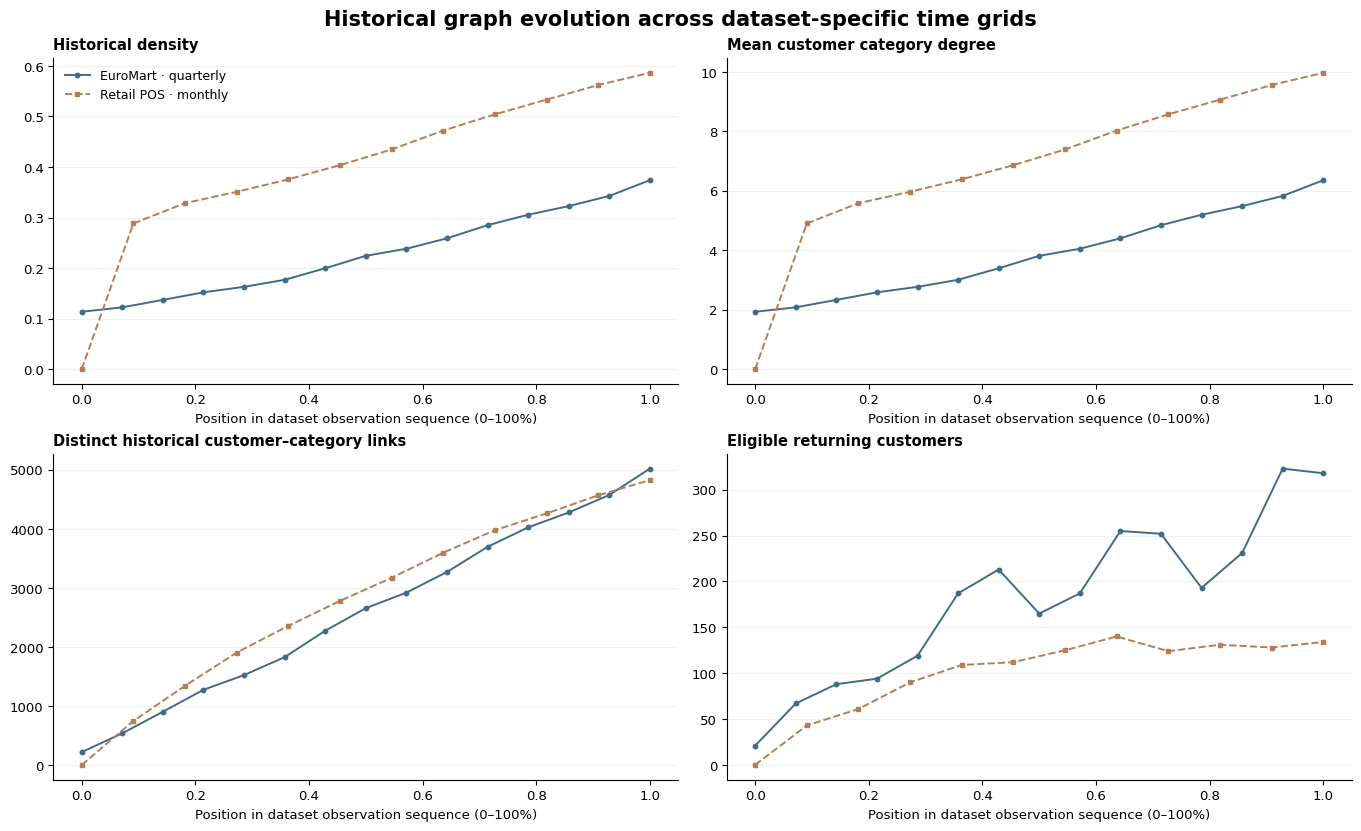

Saved temporal diagnostics: /content/drive/MyDrive/SC4020-DataMining/results/v6/run2_graphs/figures


In [5]:
from matplotlib.ticker import MaxNLocator

FIG_DIR = RUN2 / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

metrics = [
    ('density_fixed_17', 'Historical density', '{:.1%}'),
    ('mean_customer_degree', 'Mean customer category degree', '{:.1f}'),
    ('unique_edges', 'Distinct historical customer–category links', '{:,.0f}'),
    ('eligible_customers', 'Eligible returning customers', '{:,.0f}'),
]

with plt.rc_context({'font.family':'DejaVu Sans','font.size':9.5,
                     'axes.spines.top':False,'axes.spines.right':False,
                     'figure.facecolor':'white','savefig.facecolor':'white'}):
    fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.2), constrained_layout=True)
    for ax, (field, title, fmt) in zip(axes.ravel(), metrics):
        for df, label, color, style in [(INDEX,'EuroMart · quarterly','#416C88','o-'),
                                        (POS_INDEX,'Retail POS · monthly','#B67E55','s--')]:
            if field in df.columns:
                # Normalise the x-axis to fraction through the target sequence,
                # since quarter and month units must not be treated as identical.
                x = np.linspace(0, 1, len(df))
                ax.plot(x, df[field].to_numpy(), style, color=color, markersize=3.2,
                        linewidth=1.4, label=label)
        ax.set_title(title, loc='left', fontweight='bold', fontsize=10.5)
        ax.set_xlabel('Position in dataset observation sequence (0–100%)')
        ax.grid(axis='y', alpha=.18)
    axes[0,0].legend(loc='best',frameon=False,fontsize=9)
    fig.suptitle('Historical graph evolution across dataset-specific time grids',
                 fontweight='bold',fontsize=15)
    for ext in ('png','pdf'):
        fig.savefig(FIG_DIR/f'historical_graph_evolution.{ext}', dpi=200)
    display(fig)
    plt.close(fig)
print('Saved temporal diagnostics:', FIG_DIR)

## 6. Submission figures · Run 9 scientific faceted layout

**Final targets:** EuroMart `2014Q4` (quarterly v5 graph) and Retail POS `2024-12` (monthly v3 graph). **Panels A/B share the exact same 100 eligible customers** in descending historical degree; panels C–G use all customers and all 17 categories. The same colours, aspect ratios, titles and colour scales are applied to both datasets. These figures *never* include held-out purchase labels in the graph.

In [6]:
from matplotlib.colors import ListedColormap, TwoSlopeNorm
from matplotlib.collections import LineCollection
from scipy.sparse import csr_matrix
from zipfile import ZipFile, ZIP_DEFLATED

REPORT_FACET_DIR = RUN2 / 'report_facets'
REPORT_FACET_DIR.mkdir(parents=True, exist_ok=True)
REPORT_SEED = 42
REPORT_SAMPLE_SIZE = 100
REPORT_PNG_DPI = 250
# All three formats by default; set ('png',) for a quick preview run.
REPORT_EXPORT_FORMATS = ('png', 'pdf', 'svg')
REPORT_SNAPSHOTS = [
  {'dataset':'euromart','target_period':'2014Q4','display':'EuroMart Retail','stem':'euromart_2014Q4'},
  {'dataset':'retail_pos','target_period':'2024-12','display':'Retail POS','stem':'retail_pos_2024-12'},
]

def _report_snapshot_id(spec):
    return (spec['dataset'], spec['target_period'])

def load_snapshot(sid):
    dataset, period = sid
    a, path, rec = read_verified_npz(dataset,period)
    u,c = a['edge_index_bipartite']
    return {'path':path,'meta':{'relative_path':str(path.relative_to(ROOT))},
            'n_customer':a['customer_features'].shape[0],
            'n_category':a['category_features'].shape[0],
            'edge':(u,c),'customer_features':a['customer_features'],
            'category_features':a['category_features'],
            'extras':{'eligible_customer_idx':a['eligible_customer_idx']}}

def full_bipartite_matrix(snap):
    u,c = snap['edge']
    mat = csr_matrix((np.ones(len(u),dtype=np.int32),(u,c)),
                     shape=(snap['n_customer'],snap['n_category']),dtype=np.int32)
    mat.data[:] = 1  # graph is binary, even if raw history has repeat purchases
    mat.eliminate_zeros()
    return mat

def category_overlap(mat):
    intersection=(mat.T@mat).toarray().astype(float)
    degree=np.asarray(mat.sum(axis=0)).ravel()
    union=degree[:,None]+degree[None,:]-intersection
    jac=np.divide(intersection,union,where=union>0,out=np.zeros_like(intersection))
    np.fill_diagonal(jac,np.where(degree>0,1.,0.))
    return intersection, jac

def _report_sample_eligible(snap,degree,seed,size):
    eligible=snap['extras'].get('eligible_customer_idx')
    if eligible is None: raise ValueError('eligible_customer_idx missing')
    eligible=np.unique(np.asarray(eligible,dtype=np.int64).reshape(-1))
    if not len(eligible): raise ValueError('No eligible customers for selected target')
    if eligible.min()<0 or eligible.max()>=snap['n_customer']:
        raise AssertionError('Eligible indices outside customer registry')
    picked=np.random.default_rng(seed).choice(eligible,size=min(size,len(eligible)),replace=False)
    picked=picked[np.argsort(-degree[picked],kind='stable')]
    return picked,len(eligible)

In [7]:
def render_open_facet(spec):

    # --------------------------------------------------------
    # 1. Load historical graph and features
    # --------------------------------------------------------

    sid = _report_snapshot_id(spec)
    snap = load_snapshot(sid)

    mat = full_bipartite_matrix(snap)
    n, m = mat.shape

    degree_u = np.asarray(
        mat.sum(axis=1)
    ).ravel().astype(int)

    degree_c = np.asarray(
        mat.sum(axis=0)
    ).ravel().astype(int)

    _, jaccard = category_overlap(mat)

    picked, n_eligible = _report_sample_eligible(
        snap,
        degree_u,
        REPORT_SEED,
        REPORT_SAMPLE_SIZE,
    )

    sampled = (
        mat[picked]
        .toarray()
        .astype(np.uint8)
    )

    n_edges = int(mat.nnz)
    sample_edges = int(sampled.sum())
    density = n_edges / (n * m)

    customer_features = np.asarray(
        snap["customer_features"],
        dtype=float,
    )

    category_features = np.asarray(
        snap["category_features"],
        dtype=float,
    )

    blue = "#416C88"
    orange = "#B67E55"
    grey = "#555555"

    # --------------------------------------------------------
    # 2. Scientific styling and uniform grid
    # --------------------------------------------------------

    with plt.rc_context({
        "font.family": "DejaVu Sans",
        "font.size": 9.5,
        "axes.labelsize": 9.5,
        "xtick.labelsize": 8.5,
        "ytick.labelsize": 8.5,
        "axes.linewidth": 0.7,
        "axes.edgecolor": "#555555",
        "figure.facecolor": "white",
        "savefig.facecolor": "white",
        "pdf.fonttype": 42,
        "svg.fonttype": "none",
    }):

        fig = plt.figure(
            figsize=(17.5, 14.4),
            facecolor="white",
        )

        gs = fig.add_gridspec(
            3, 6,
            left=0.062,
            right=0.948,
            top=0.852,
            bottom=0.086,
            wspace=0.64,
            hspace=0.45,
            height_ratios=(1.43, 1.06, 1.25),
        )

        ax_a = fig.add_subplot(gs[0, :3])
        ax_b = fig.add_subplot(gs[0, 3:])

        ax_c = fig.add_subplot(gs[1, :2])
        ax_d = fig.add_subplot(gs[1, 2:4])
        ax_e = fig.add_subplot(gs[1, 4:])

        ax_f = fig.add_subplot(gs[2, :3])
        ax_g = fig.add_subplot(gs[2, 3:])

        # ----------------------------------------------------
        # Figure heading
        # ----------------------------------------------------

        fig.text(
            0.062, 0.970,
            (
                f"{spec['display']} — "
                "historical customer–category graph"
            ),
            fontsize=16,
            fontweight="bold",
            va="top",
        )

        fig.text(
            0.062, 0.943,
            (
                f"Target: {spec['target_period']}   |   "
                f"{n:,} customers   |   "
                f"{m} categories   |   "
                f"{n_edges:,} historical links   |   "
                f"Density: {100 * density:.1f}%"
            ),
            fontsize=10,
            va="top",
        )

        fig.text(
            0.062, 0.922,
            (
                "Constructed from cleaned, canonicalised "
                "transactions strictly preceding the "
                "prediction period."
            ),
            fontsize=9,
            color=grey,
            va="top",
        )

        # ----------------------------------------------------
        # Uniform panel titles without borders
        # ----------------------------------------------------

        def panel(ax, letter, title, detail):

            ax.text(
                0, 1.11,
                f"{letter}   {title}",
                transform=ax.transAxes,
                fontsize=11.5,
                fontweight="bold",
                ha="left",
                va="bottom",
                clip_on=False,
            )

            ax.text(
                0, 1.035,
                detail,
                transform=ax.transAxes,
                fontsize=9,
                color=grey,
                ha="left",
                va="bottom",
                clip_on=False,
            )

            ax.spines[
                ["top", "right"]
            ].set_visible(False)

        def statistical_axis(ax):

            ax.grid(
                axis="y",
                color="#E1E4E7",
                linewidth=0.5,
                alpha=0.65,
            )

            ax.set_axisbelow(True)

        # ====================================================
        # A | BIPARTITE NETWORK
        # ====================================================

        customer_y = np.linspace(
            0.97, 0.03, len(picked)
        ) if len(picked) > 1 else np.array([0.5])

        category_y = np.linspace(
            0.97, 0.03, m
        )

        rows, cols = np.nonzero(sampled)

        segments = np.stack(
            [
                np.column_stack([
                    np.zeros(len(rows)),
                    customer_y[rows],
                ]),
                np.column_stack([
                    np.ones(len(rows)),
                    category_y[cols],
                ]),
            ],
            axis=1,
        )

        ax_a.add_collection(
            LineCollection(
                segments,
                colors=blue,
                linewidths=0.42,
                alpha=0.14,
                rasterized=True,
                zorder=1,
            )
        )

        ax_a.scatter(
            np.zeros(len(picked)),
            customer_y,
            s=8,
            color=blue,
            edgecolors="none",
            zorder=2,
        )

        ax_a.scatter(
            np.ones(m),
            category_y,
            s=20 + 75 * degree_c
              / max(int(degree_c.max()), 1),
            color=orange,
            edgecolors="white",
            linewidths=0.5,
            zorder=3,
        )

        for j, y in enumerate(category_y):

            ax_a.text(
                1.04, y,
                f"C{j}",
                fontsize=8,
                va="center",
            )

        ax_a.set_xlim(-0.04, 1.18)
        ax_a.set_ylim(0, 1)

        ax_a.set_xticks(
            [0, 1],
            ["Customers", "Categories"],
        )

        ax_a.set_yticks([])

        for spine in ax_a.spines.values():
            spine.set_visible(False)

        panel(
            ax_a,
            "A",
            "Sampled bipartite network",
            (
                f"n = {len(picked)} of {n_eligible} "
                f"eligible customers; "
                f"{sample_edges:,} historical links"
            ),
        )

        # ====================================================
        # B | BINARY ADJACENCY MATRIX
        # ====================================================

        ax_b.imshow(
            sampled,
            cmap=ListedColormap([
                "#FFFFFF", blue
            ]),
            aspect="auto",
            interpolation="nearest",
            vmin=0,
            vmax=1,
        )

        ax_b.set_xticks(
            np.arange(m),
            [f"C{i}" for i in range(m)],
            rotation=90,
        )

        y_ticks = np.unique(
            np.linspace(
                0,
                len(picked)-1,
                5,
            ).astype(int)
        )

        ax_b.set_yticks(
            y_ticks,
            y_ticks + 1,
        )

        ax_b.set_xlabel("Category index")
        ax_b.set_ylabel("Sampled customer rank")

        panel(
            ax_b,
            "B",
            "Binary adjacency matrix",
            (
                f"n = {len(picked)} matched customers "
                f"× {m} categories"
            ),
        )

        # ====================================================
        # C | CUSTOMER DEGREE DISTRIBUTION
        # ====================================================

        degree_counts = np.bincount(
            degree_u,
            minlength=m+1,
        )

        ax_c.bar(
            np.arange(m+1),
            degree_counts[:m+1],
            color=blue,
            width=0.78,
        )

        ax_c.axvline(
            degree_u.mean(),
            color=orange,
            linestyle="--",
            linewidth=1.4,
            label=f"Mean = {degree_u.mean():.2f}",
        )

        ax_c.set_xlim(-0.5, m+0.5)

        ax_c.set_xticks(
            np.arange(0, m+1, 2)
        )

        ax_c.set_xlabel(
            "Distinct categories per customer"
        )

        ax_c.set_ylabel("Customers")

        ax_c.legend(
            loc="upper right",
            fontsize=8,
            frameon=False,
        )

        statistical_axis(ax_c)

        panel(
            ax_c,
            "C",
            "Customer degree",
            f"n = {n:,} customers",
        )

        # ====================================================
        # D | CATEGORY POPULARITY
        # ====================================================

        ax_d.bar(
            np.arange(m),
            degree_c,
            color=orange,
            width=0.78,
        )

        ax_d.set_xlim(-0.5, m-0.5)

        ax_d.set_xticks(
            np.arange(0, m, 2)
        )

        ax_d.set_xlabel("Category index")
        ax_d.set_ylabel("Linked customers")

        statistical_axis(ax_d)

        panel(
            ax_d,
            "D",
            "Category popularity",
            (
                f"n = {m} categories; "
                f"{n_edges:,} distinct links"
            ),
        )

        # ====================================================
        # E | CATEGORY JACCARD SIMILARITY
        # ====================================================

        im_e = ax_e.imshow(
            jaccard,
            cmap="viridis",
            vmin=0,
            vmax=1,
            aspect="auto",
            interpolation="nearest",
        )

        ax_e.set_xticks(
            np.arange(0, m, 2)
        )

        ax_e.set_yticks(
            np.arange(0, m, 2)
        )

        ax_e.set_xlabel("Category index")
        ax_e.set_ylabel("Category index")

        cb_e = fig.colorbar(
            im_e,
            ax=ax_e,
            fraction=0.045,
            pad=0.025,
        )

        cb_e.ax.tick_params(labelsize=8)

        panel(
            ax_e,
            "E",
            "Jaccard similarity",
            (
                f"n = {m} categories; "
                "shared historical customers"
            ),
        )

        # ====================================================
        # F | CUSTOMER NODE FEATURES
        # ====================================================

        feature_columns = [
            col[np.isfinite(col)]
            for col in customer_features.T
        ]

        bp = ax_f.boxplot(
            feature_columns,
            patch_artist=True,
            widths=0.55,
            medianprops={
                "color": orange,
                "linewidth": 1.3,
            },
            flierprops={
                "marker": ".",
                "markersize": 2.5,
                "markerfacecolor": blue,
                "markeredgecolor": "none",
                "alpha": 0.35,
            },
        )

        for patch in bp["boxes"]:
            patch.set_facecolor("#D9E6ED")
            patch.set_edgecolor(blue)

        ax_f.set_xticks(
            np.arange(
                1,
                customer_features.shape[1]+1,
            ),
            [
                f"F{i}"
                for i in range(
                    customer_features.shape[1]
                )
            ],
        )

        ax_f.set_xlabel("Feature index")
        ax_f.set_ylabel("NPZ feature value")

        statistical_axis(ax_f)

        panel(
            ax_f,
            "F",
            "Customer node features",
            (
                f"n = {n:,} customers; "
                f"{customer_features.shape[1]} features"
            ),
        )

        # ====================================================
        # G | CATEGORY NODE FEATURES
        # ====================================================

        finite = category_features[
            np.isfinite(category_features)
        ]

        bound = max(
            float(np.max(np.abs(finite)))
            if finite.size else 1.0,
            0.001,
        )

        im_g = ax_g.imshow(
            np.ma.masked_invalid(category_features),
            cmap="coolwarm",
            aspect="auto",
            interpolation="nearest",
            norm=TwoSlopeNorm(
                vmin=-bound,
                vcenter=0,
                vmax=bound,
            ),
        )

        ax_g.set_xticks(
            np.arange(
                category_features.shape[1]
            ),
            [
                f"F{i}"
                for i in range(
                    category_features.shape[1]
                )
            ],
        )

        ax_g.set_yticks(
            np.arange(m),
            [f"C{i}" for i in range(m)],
        )

        ax_g.set_xlabel("Feature index")
        ax_g.set_ylabel("Category index")

        cb_g = fig.colorbar(
            im_g,
            ax=ax_g,
            fraction=0.035,
            pad=0.030,
        )

        cb_g.ax.tick_params(labelsize=8)

        panel(
            ax_g,
            "G",
            "Category node features",
            (
                f"n = {m} categories; "
                f"{category_features.shape[1]} features"
            ),
        )

        # ----------------------------------------------------
        # Figure note
        # ----------------------------------------------------

        fig.text(
            0.062, 0.045,
            (
                "A–B: identical sampled eligible customers; "
                "C–G: complete historical snapshot. "
                "A link denotes at least one prior purchase."
            ),
            fontsize=9,
            color=grey,
        )

        # ----------------------------------------------------
        # Export
        # ----------------------------------------------------

        stem = (
            REPORT_FACET_DIR
            / f"{spec['stem']}_faceted"
        )

        saved_paths = []

        for extension in REPORT_EXPORT_FORMATS:

            path = stem.with_suffix(
                "." + extension
            )

            fig.savefig(
                path,
                dpi=REPORT_PNG_DPI,
                bbox_inches="tight",
                facecolor="white",
            )

            saved_paths.append(str(path))

        display(fig)
        plt.close(fig)

    # --------------------------------------------------------
    # Save sampled customer indices
    # --------------------------------------------------------

    selected_path = (
        REPORT_FACET_DIR
        / f"{spec['stem']}_selected_eligible_customers.csv"
    )

    pd.DataFrame({
        "order_in_A_and_B": np.arange(
            1, len(picked)+1
        ),
        "snapshot_customer_idx": picked,
        "historical_degree": degree_u[picked],
    }).to_csv(
        selected_path,
        index=False,
    )

    return {
        "dataset": spec["display"],
        "snapshot_id": sid,
        "target_period": spec["target_period"],
        "source_npz": str(
            snap["meta"]["relative_path"]
        ),
        "customers": n,
        "categories": m,
        "historical_unique_edges": n_edges,
        "density": density,
        "eligible_customers": n_eligible,
        "sampled_eligible_customers": len(picked),
        "rendered_sample_edges": sample_edges,
        "sample_seed": REPORT_SEED,
        "plots": saved_paths,
        "customer_indices_csv": str(selected_path),
    }

### 6.1 Generate both seven-panel faceted figures and export artifacts

This cell displays **both** report figures and writes PNG/PDF/SVG files, sample-customer CSVs, a provenance manifest and a ZIP. Repeat runs are deterministic and replace only files inside the **new `results/v6/` figure directory**.

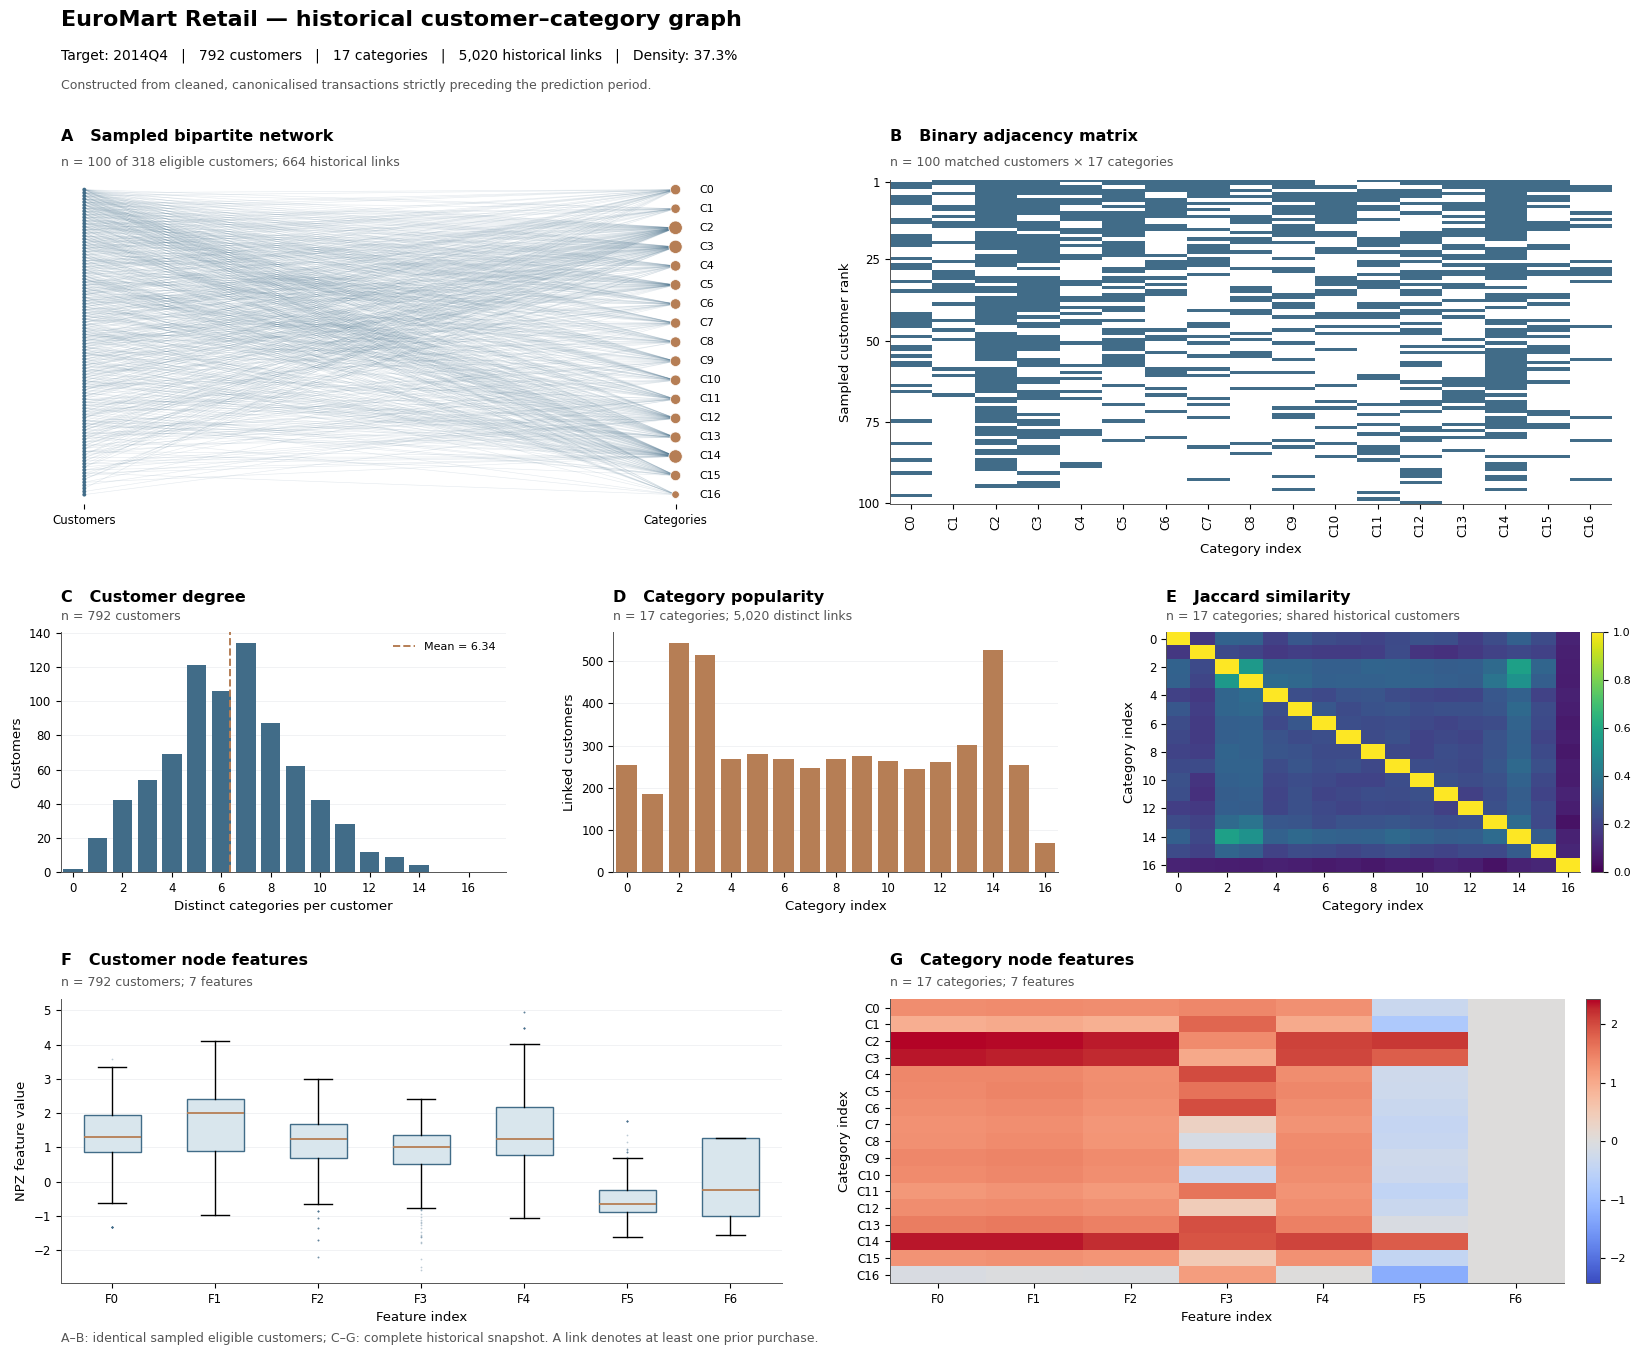

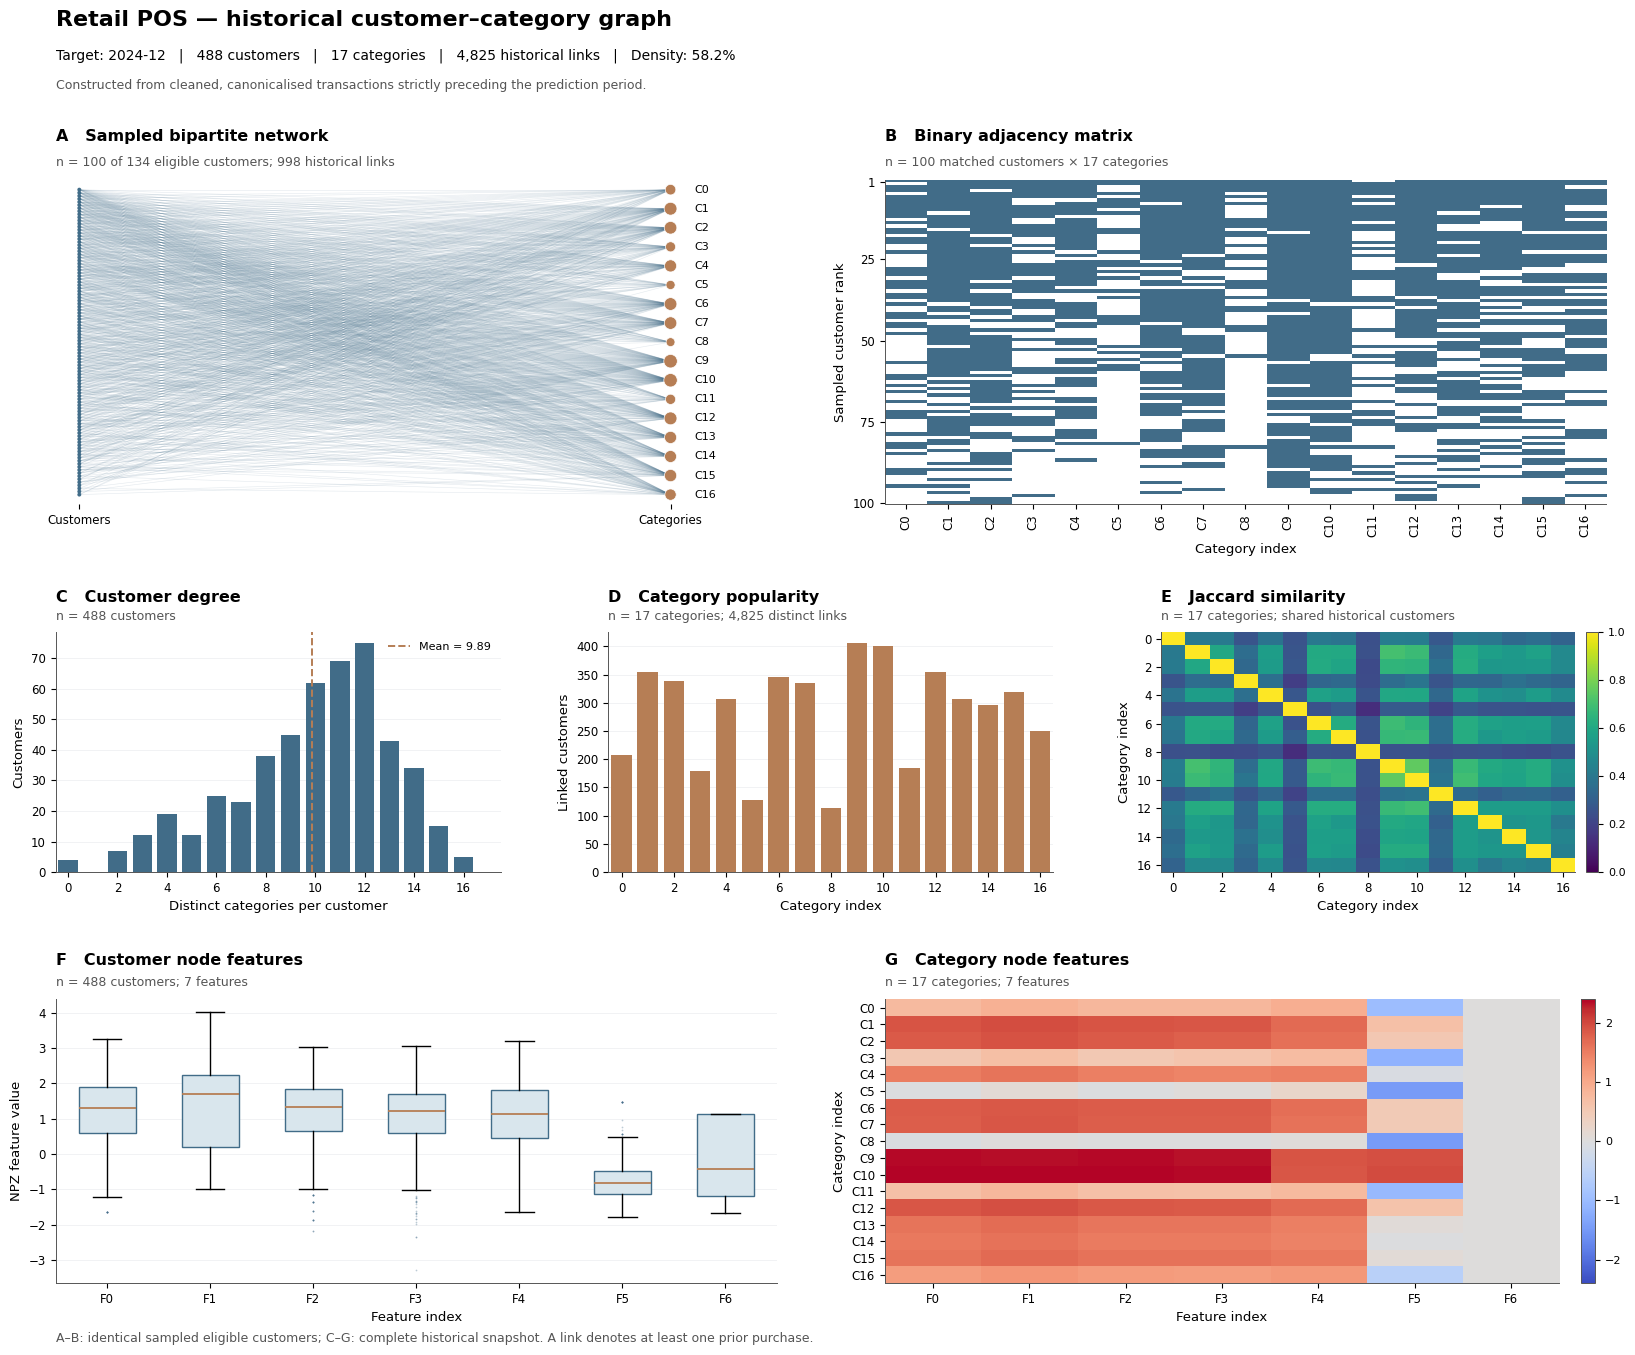


Report figures saved to: /content/drive/MyDrive/SC4020-DataMining/results/v6/run2_graphs/report_facets
Figure-only ZIP: /content/drive/MyDrive/SC4020-DataMining/results/v6/run2_graphs/report_facets/report_facets_only.zip
  EuroMart Retail: 5,020 full-graph links; 100 selected eligible customers; 664 visible edges in panels A/B
  Retail POS: 4,825 full-graph links; 100 selected eligible customers; 998 visible edges in panels A/B


In [8]:
REPORT_FACET_RESULTS = [render_open_facet(spec) for spec in REPORT_SNAPSHOTS]
manifest_path = REPORT_FACET_DIR / 'report_facets_manifest.json'
manifest_path.write_text(json.dumps(REPORT_FACET_RESULTS, indent=2), encoding='utf-8')

zip_path = REPORT_FACET_DIR / 'report_facets_only.zip'
with ZipFile(zip_path, 'w', ZIP_DEFLATED, compresslevel=6) as zf:
    for result in REPORT_FACET_RESULTS:
        for name in result['plots'] + [result['customer_indices_csv']]:
            zf.write(name, arcname=Path(name).name)
    zf.write(manifest_path, arcname=manifest_path.name)

print('\nReport figures saved to:', REPORT_FACET_DIR)
print('Figure-only ZIP:', zip_path)
for r in REPORT_FACET_RESULTS:
    print(f'  {r["dataset"]}: {r["historical_unique_edges"]:,} full-graph links; '
          f'{r["sampled_eligible_customers"]} selected eligible customers; '
          f'{r["rendered_sample_edges"]:,} visible edges in panels A/B')

## 7. Final reproducibility checks and submission inventory

The final cell checks the expected report figures and records exactly which immutable NPZs produced them. Nothing in `graph_data/v3` or existing incompatible `graph_data/v5` snapshots is modified.

In [9]:
required_files = [
    REPORT_FACET_DIR / f'{stem}_faceted.{ext}'
    for stem in ('euromart_2014Q4','retail_pos_2024-12')
    for ext in REPORT_EXPORT_FORMATS
]
assert all(p.is_file() and p.stat().st_size>1024 for p in required_files)
assert all(r['sampled_eligible_customers']==100 for r in REPORT_FACET_RESULTS)
assert {(r['dataset'], r['historical_unique_edges']) for r in REPORT_FACET_RESULTS} == {
    ('EuroMart Retail',5020), ('Retail POS',4825)}

completion = {
    'notebook': 'Run 2 v6 (visualisation integration)',
    'euromart_npz_root': str(SNAPDIR.relative_to(ROOT)),
    'retail_pos_npz_root': str(POS_SNAPDIR.relative_to(ROOT)),
    'euromart_snapshot_index_sha256': sha256(EURO/'snapshot_index.csv'),
    'retail_pos_snapshot_index_sha256': sha256(POS_INDEX_PATH),
    'faceted_figure_records': REPORT_FACET_RESULTS,
    'figure_zip': str(zip_path.relative_to(ROOT)),
    'status': 'completed',
}
write_json(RUN2/'manifests/run2_v6_completion.json',completion)
print('✓ All construction, reproducibility and figure audits passed.')
print('✓ Notebook submission can be renamed to the required team filename without altering graph artifacts.')
display(SUMMARY)

✓ All construction, reproducibility and figure audits passed.
✓ Notebook submission can be renamed to the required team filename without altering graph artifacts.


,dataset,period,snapshots,train,validation,test,final_target
0,EuroMart Retail,quarter,15,10,2,3,2014Q4
1,Retail POS,month,12,8,2,2,2024-12
